# Módulo 3 - Punto 3.1: Descriptores morfométricos y de textura en el frame segmentado

**Objetivo.** Extraer métricas de forma de la pupila y de textura de la pupila y del iris en un frame del video, a partir de la ROI segmentada (Módulo 2) y cuantizada a 32 y 64 niveles de gris.

Toda la lógica está en `src/modulo3/descriptores.py` y los parámetros en la sección `modulo3` de `config.yaml`; este notebook llama a las funciones, muestra los resultados y los discute. Las figuras y tablas se guardan en `results/modulo3/`.

## 0. Configuración del entorno e importaciones

In [1]:
# --- Imports de la librería estándar ---
import sys
from pathlib import Path

# --- Configurar la raíz del repositorio ---
# Se sube de carpeta hasta encontrar config.yaml: esa es la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import cv2
from IPython.display import display

from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm
from src.modulo1 import calidad_filtrado as cf
from src.modulo2 import segmentacion as seg
from src.modulo3 import descriptores as de   # funciones del punto 3.1

# --- Estilo de las figuras (el mismo del Módulo 4) ---
COLOR_CANAL = {"R": "#d0453a", "G": "#2e9e5b", "B": "#2a78d6"}
COLOR_REGION = {"pupila": "#eda100", "iris": "#2a78d6"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "font.size": 10,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 3)

## 1. Frame de trabajo, segmentación y regiones

Se toma el frame del video de `entrada.video_path` en el instante `modulo3.tiempo_frame_s` (5 s, con la luz encendida).

La máscara de la pupila sale de `de.mascara_pupila`, que encadena el pipeline del Módulo 2 (`seg.segmentar_pupila`: grises → CLAHE → estimación de centro y radio → Watershed sobre el gradiente de Sobel) con la operación morfológica elegida en 2.2 (**erosión, k = 3, 2 iteraciones**, la de mayor Dice contra la anotación manual) y se queda con la componente conexa más grande.

Para la textura se definen dos regiones:

* **Pupila**: la máscara anterior.
* **Iris (estroma)**: disco de 0,85·r_iris alrededor del centro del iris (que da `seg.estimar_pupila(..., devolver_iris=True)`), sin la pupila dilatada 2 px (su borde mezcla los dos tejidos), sin las filas tapadas por el párpado superior y sin los **reflejos corneales**, detectados como los píxeles más claros que la mediana del iris + 3·MAD.

In [2]:
cfg = cargar_config(raiz / "config.yaml")
c3 = cfg["modulo3"]

carpeta_res = raiz / "results" / "modulo3"
carpeta_res.mkdir(parents=True, exist_ok=True)

# Frame del video y ROI (la misma ROI de config.yaml que en los módulos anteriores)
ruta_video = raiz / cfg["entrada"]["video_path"]
frame = cm.extraer_frame(ruta_video, c3["tiempo_frame_s"])
roi = cm.recortar_roi(frame, cfg["roi"])
gris = cf.conv_grises(roi)

# Máscara de la pupila (Módulo 2 + erosión) y círculo del iris --> se usan las mismas funciones 
# que en el módulo 2, pero ahora se devuelven los resultados en un diccionario para poder acceder a ellos por nombre.
res = de.mascara_pupila(roi, cfg)
if res["mascara"] is None:
    raise RuntimeError("No se encontró la pupila en el frame de trabajo.")
mascara = res["mascara"]
_, iris = seg.estimar_pupila(res["gris"], devolver_iris=True)

# Regiones de textura
reg_iris = de.region_iris(gris, mascara, iris, **c3["region_iris"])
regiones = {"pupila": mascara > 0, "iris": reg_iris}

print(f"Frame t = {c3['tiempo_frame_s']} s  |  ROI {roi.shape[1]}×{roi.shape[0]} px")
print(f"Pupila estimada (cx, cy, r) = {res['pupila']}  |  iris (cx, cy, r) = {iris}")
print({k: int(v.sum()) for k, v in regiones.items()}, "píxeles por región")

Frame t = 5.0 s  |  ROI 242×134 px
Pupila estimada (cx, cy, r) = (112.0, 60.0, 10.0)  |  iris (cx, cy, r) = (110.0, 62.0, 34.0)
{'pupila': 204, 'iris': 2012} píxeles por región


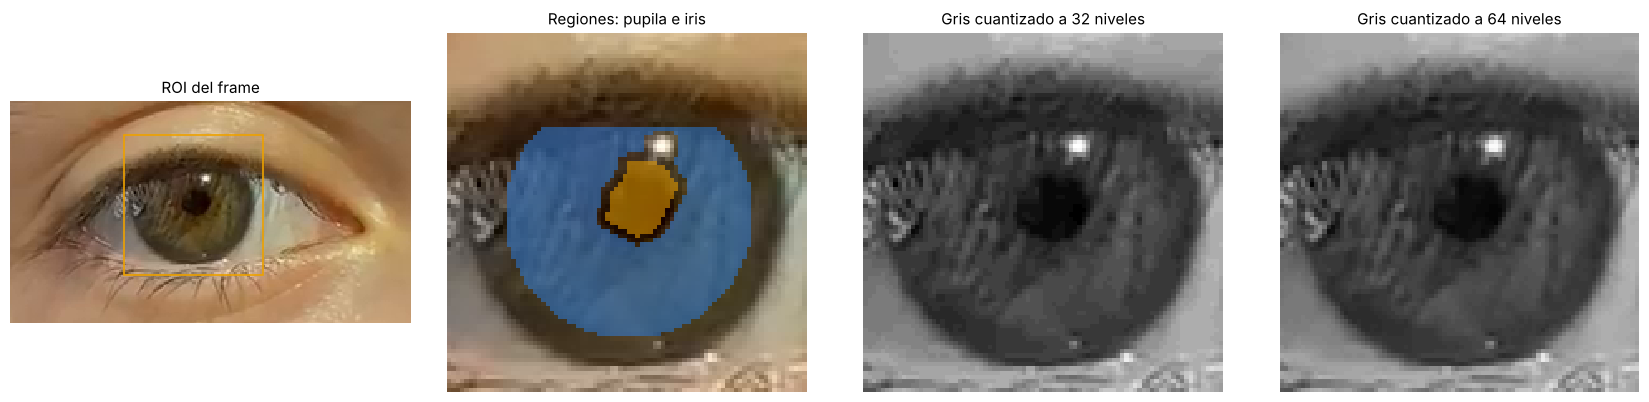

In [3]:
# ROI con las regiones y versión cuantizada a 32 y 64 niveles
niveles = c3["niveles_gris"]
icx, icy, ir = iris
lado = int(1.25 * ir)                      # zoom alrededor del iris
zx0, zy0 = max(int(icx) - lado, 0), max(int(icy) - lado, 0)
zoom = (slice(zy0, int(icy) + lado), slice(zx0, int(icx) + lado))

# Se visualizan los resultados de la segmentación y la cuantización de niveles de gris
vista = roi.copy()
for nombre, reg in regiones.items():
    rgb = np.array([int(COLOR_REGION[nombre][i:i + 2], 16) for i in (1, 3, 5)])
    vista[reg] = (0.45 * vista[reg] + 0.55 * rgb).astype(np.uint8)

paneles = [("ROI del frame", roi, None), ("Regiones: pupila e iris", vista[zoom], None)]
for L in niveles:
    q = de.cuantizar_niveles(gris, L)
    paneles.append((f"Gris cuantizado a {L} niveles", q[zoom], L - 1))

fig, ejes = plt.subplots(1, len(paneles), figsize=(4.2 * len(paneles), 4))
for ax, (titulo, im, vmax) in zip(ejes, paneles):
    ax.imshow(im, cmap="gray", vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_title(titulo)
    ax.axis("off")
ejes[0].add_patch(plt.Rectangle((zx0, zy0), 2 * lado, 2 * lado, fill=False, ec="#eda100", lw=1.2))
plt.tight_layout()
fig.savefig(carpeta_res / "3_1_1_frame_regiones.png", dpi=150, bbox_inches="tight")
plt.show()

**Regiones.** La pupila ocupa 204 px y el iris 2012 px. En la máscara del iris (azul) se ven los recortes: arriba, la franja tapada por el párpado y las pestañas; el reflejo especular de la linterna (el punto blanco arriba a la derecha de la pupila), detectado como reflejo; y el anillo de 2 px alrededor de la pupila. A 32 niveles la ROI ya no muestra los 256 grises, pero se siguen viendo las estrías del estroma y las criptas; entre 32 y 64 niveles casi no hay diferencia a la vista, porque el iris solo ocupa unos 10 a 15 de los 32 niveles (ver los histogramas de la sección 3).

## 2. Descriptores morfométricos (forma)

`de.morfometria` calcula, sobre la máscara binaria:

* **Área** A = cantidad de píxeles, y **diámetro equivalente** D = 2·√(A/π).
* **Perímetro** P = largo del contorno externo (`cv2.findContours` + `cv2.arcLength`; pasos de 1 px en horizontal/vertical y √2 en diagonal).
* **Centroide** (X_c, Y_c) = (m₁₀/m₀₀, m₀₁/m₀₀), con los momentos de la región.
* **Circularidad** C = 4π·A_c/P²: vale 1 en un círculo y baja con la irregularidad. A_c es el área encerrada por el mismo contorno con que se mide P (si se mezclara con el conteo de píxeles, en un objeto de ~15 px de diámetro C daría mayor que 1).
* **Excentricidad** e = √(1 − λ₂/λ₁), con λ₁ ≥ λ₂ los autovalores de la matriz de momentos centrales de orden 2 (la "covarianza" de la región). e = 0 en un círculo y tiende a 1 en una elipse muy alargada. Con esos mismos momentos se obtiene la **elipse equivalente** (ejes 4·√λ y orientación).

Para ver cuánto dependen los descriptores de la segmentación, se calculan también sobre la máscara de Watershed **sin** la erosión.

In [4]:
# morfometría calcula los parámetros: área, perímetro, centroide, elipse equivalente y circularidad de la pupila (máscara) y del iris (círculo)
morf_final = de.morfometria(mascara)        # Le calculamos los parámetros a la máscara completa
morf_ws = de.morfometria(de.componente_principal(seg.segmentar_pupila(roi, cfg)["mascara"]))  # Le calculamos los parámetros sólo a la parte unida de la pupila (componente_principal elimina los píxeles aislados) sin la erosión, como en el Módulo 2
tabla_morf = pd.DataFrame({"Watershed + erosión (final)": morf_final, "Watershed sin morfología": morf_ws})
tabla_morf.to_csv(carpeta_res / "3_1_morfometria.csv")
display(tabla_morf)

# El centroide está en coordenadas de la ROI; en el frame completo se suma la esquina de la ROI
x0, _, y0, _ = cm.roi_a_pixeles(frame.shape, cfg["roi"])
print(f"Centroide en el frame completo: (Xc, Yc) = ({morf_final['cx'] + x0:.1f}, {morf_final['cy'] + y0:.1f}) px")

,Watershed + erosión (final),Watershed sin morfología
area_px,204.000,314.000
perimetro_px,54.284,67.941
cx,112.922,112.882
cy,58.123,57.962
diametro_eq_px,16.116,19.995
circularidad,0.768,0.773
excentricidad,0.661,0.600
eje_mayor_px,18.745,22.533
eje_menor_px,14.066,18.031
orientacion_grados,-59.909,-62.845


Centroide en el frame completo: (Xc, Yc) = (319.9, 416.1) px


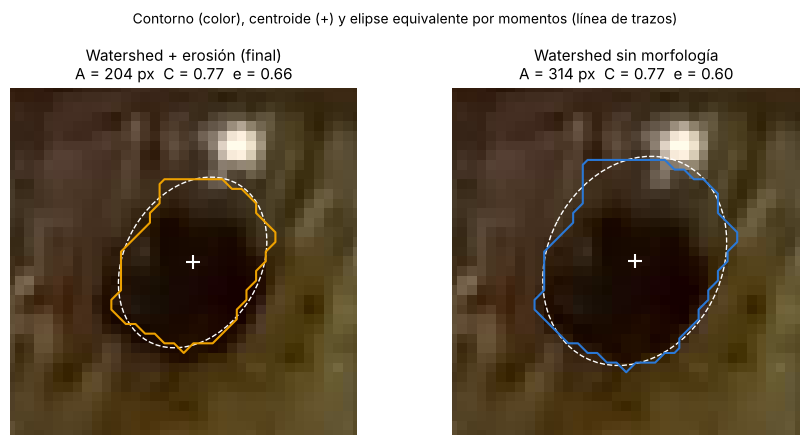

In [5]:
# Contorno, centroide y elipse equivalente (zoom sobre la pupila) --> esto muestra los resultados sobre la ROI de la pupila
m = morf_final
lado_p = 18
px0, py0 = int(m["cx"]) - lado_p, int(m["cy"]) - lado_p
fig, ejes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, (titulo, mk, mm, col) in zip(ejes, [
        ("Watershed + erosión (final)", mascara, morf_final, "#eda100"),
        ("Watershed sin morfología", seg.segmentar_pupila(roi, cfg)["mascara"], morf_ws, "#2a78d6")]):
    ax.imshow(roi, extent=(-0.5, roi.shape[1] - 0.5, roi.shape[0] - 0.5, -0.5), interpolation="nearest")
    ax.contour(mk > 0, levels=[0.5], colors=col, linewidths=1.5)
    ax.add_patch(Ellipse((mm["cx"], mm["cy"]), mm["eje_mayor_px"], mm["eje_menor_px"],
                         angle=mm["orientacion_grados"], fill=False, ec="white", lw=1, ls="--"))
    ax.plot(mm["cx"], mm["cy"], "+", color="white", ms=10, mew=1.5)
    ax.set_xlim(px0, px0 + 2 * lado_p); ax.set_ylim(py0 + 2 * lado_p, py0)
    ax.set_title(f"{titulo}\nA = {mm['area_px']} px  C = {mm['circularidad']:.2f}  e = {mm['excentricidad']:.2f}")
    ax.axis("off")
plt.suptitle("Contorno (color), centroide (+) y elipse equivalente por momentos (línea de trazos)", y=1.0, fontsize=10)
plt.tight_layout()
fig.savefig(carpeta_res / "3_1_2_morfometria.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (forma).** Con la máscara final, la pupila tiene **A = 204 px** (diámetro equivalente 16,1 px, ≈ 2,8 mm con la escala del iris de 3.2), **P = 54,3 px** y su centroide está en (112,9; 58,1) px de la ROI. La forma se aleja de un círculo: **circularidad 0,77** y **excentricidad 0,66**, con el eje mayor inclinado unos −60° (de arriba a la derecha hacia abajo a la izquierda). Una pupila sana es casi circular (e < 0,3), así que esta deformación es sobre todo **de medición** y no fisiológica:

* la pupila mide ~16 px de diámetro: cada píxel del borde es ~6 % del diámetro y el contorno es una escalera;
* el borde superior derecho se deforma junto al reflejo especular de la linterna, pegado a la pupila;
* el ojo no mira de frente a la cámara: un círculo visto en ángulo se proyecta como una elipse;
* el video está comprimido (H.264) y algo desenfocado, lo que redondea y mezcla el borde.

La erosión del Módulo 2 achica el área un 35 % (314 → 204 px) pero casi no cambia el centroide (diferencia de 0,2 px), la orientación (3°) ni la circularidad (0,77 en los dos casos). Es decir, corrige el **tamaño** (en 2.2 Watershed salía 1,4–1,8 veces más grande que la anotación manual) sin cambiar la **forma**. Por eso, para la curva temporal (3.2) importa mucho qué máscara se use; para describir la regularidad de la pupila, no tanto.

## 3. Textura de primer orden (estadística del histograma)

En cada región y en cada canal (R, G, B) por separado se calcula, con `de.tabla_primer_orden`:

* **Media** μ y **desvío estándar** σ (en niveles de gris 0–255).
* **Asimetría** (skewness) = E[(x − μ)³]/σ³: positiva si el histograma tiene una cola hacia los valores claros.
* **Entropía** H = −Σ pₖ·log₂ pₖ sobre el histograma **cuantizado a 32 niveles**: mide cuán repartidos están los grises. El máximo posible es log₂ 32 = 5 bits.

Son estadísticos *globales*: no dicen nada de cómo están ordenados los píxeles en el espacio (eso lo aporta la GLCM, en la sección 4).

In [6]:
L0 = niveles[0]   # Se elige el primer nivel de cuantización para calcular los descriptores de primer orden
tabla_po = de.tabla_primer_orden(roi, regiones, L0)  # tabla_primer_orden genera la tabla, pero llama a _primer_orden (tmb en descriptores.py) que calcula los descriptores de primer orden para cada región y canal
tabla_po.to_csv(carpeta_res / "3_1_primer_orden.csv", index=False)
display(tabla_po.set_index(["region", "canal"]))

media  desvio  entropia_bits  asimetria  n_pixeles
region canal                                                     
pupila R      35.275  14.770          2.378      1.627        204
       G      18.848  16.106          2.573      1.460        204
       B       8.270  12.229          1.533      2.346        204
iris   R      79.428  12.993          2.754     -0.136       2012
       G      63.953  13.921          2.813     -0.286       2012
       B      36.840  13.267          2.779     -0.037       2012

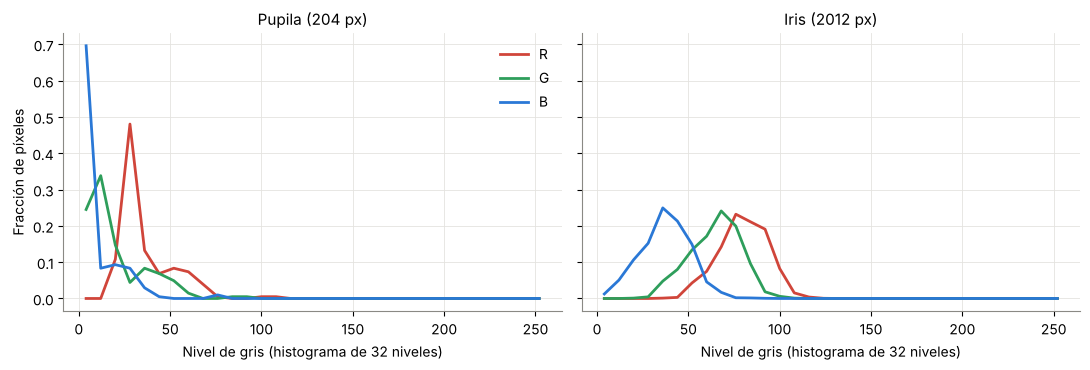

In [7]:
# Histogramas de cada canal en cada región
bordes = np.arange(L0 + 1) * 256 / L0
centros = (bordes[:-1] + bordes[1:]) / 2
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (nombre, reg) in zip(ejes, regiones.items()):
    for canal, k in de.CANALES.items():
        h, _ = np.histogram(roi[:, :, k][reg], bins=bordes)
        ax.plot(centros, h / h.sum(), "-", color=COLOR_CANAL[canal], label=canal)
    ax.set_title(f"{nombre.capitalize()} ({int(reg.sum())} px)")
    ax.set_xlabel(f"Nivel de gris (histograma de {L0} niveles)")
ejes[0].set_ylabel("Fracción de píxeles")
ejes[0].legend(frameon=False)
plt.tight_layout()
fig.savefig(carpeta_res / "3_1_3_histogramas.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (primer orden).**

* **Iris**: media R (79) > G (64) > B (37). Es un iris claro, entre verde y marrón: la melanina del estroma absorbe más el azul que el rojo. El desvío es parecido en los tres canales (13–14 niveles), con G apenas mayor. La asimetría es levemente negativa en R y G (−0,14 y −0,29): hay una cola de píxeles oscuros, que corresponden a las criptas y a los surcos del estroma y al collarete más oscuro alrededor de la pupila. La entropía es de 2,75–2,81 bits de los 5 posibles con 32 niveles: los grises del iris se concentran en unos 10 niveles. **G tiene la mayor entropía (2,81 bits) y el mayor desvío (13,9)**; R, los menores.
* **Pupila**: es mucho más oscura (B = 8, G = 19) pero **no llega a 0**. Mide ~16 px, así que el desenfoque y la compresión mezclan su interior con el iris; además el canal R siempre queda más alto (35). La asimetría es fuertemente positiva (1,5–2,3): casi todos los píxeles están cerca del negro y una cola de valores claros viene del borde y del halo del reflejo especular. B tiene la menor entropía (1,53 bits): el 70 % de los píxeles cae en el primer nivel.

Los estadísticos de primer orden ya **separan muy bien pupila e iris por la media** (de 2 a 4,5 veces más claro el iris según el canal), pero no dicen nada de la textura: un iris con las mismas intensidades desordenadas al azar daría la misma tabla.

## 4. Textura de segundo orden: matriz de co-ocurrencia (GLCM)

La GLCM P(i, j) cuenta cuántas veces un píxel de nivel *i* tiene, a una distancia *d* en la dirección θ, un vecino de nivel *j* (normalizada para que sume 1). A diferencia del histograma, describe la **organización espacial** de los grises. Se implementó en `de.glcm` para poder restringirla a una región de forma arbitraria: solo se cuentan los pares con **los dos píxeles dentro de la región** (el anillo del iris no es un rectángulo). Es simétrica (se cuentan (i, j) y (j, i)) y se promedia sobre d = 1 y 2 px y θ = 0°, 45°, 90° y 135°, para que la textura no dependa de una dirección.

Atributos de Haralick (`de.atributos_glcm`):

| Atributo | Fórmula | Alto cuando… |
|---|---|---|
| Contraste | Σ (i−j)²·P(i,j) | hay vecinos con niveles muy distintos (textura marcada) |
| Homogeneidad | Σ P(i,j)/(1+(i−j)²) | los vecinos tienen niveles parecidos |
| Energía (ASM) | Σ P(i,j)² | pocas combinaciones se repiten mucho (región uniforme) |
| Correlación | Σ (i−μᵢ)(j−μⱼ)·P(i,j)/(σᵢσⱼ) | el nivel de un píxel predice linealmente el del vecino |

**Verificación.** Antes de usarla, se compara la implementación propia con `graycomatrix`/`graycoprops` de scikit-image sobre la ROI completa (región rectangular, donde las dos deben coincidir). scikit-image llama *energy* a √ASM, por eso se compara contra su `ASM`.

In [8]:
from skimage.feature import graycomatrix, graycoprops

idx = de.cuantizar_niveles(roi[:, :, 1], L0)          # canal G, 32 niveles
toda = np.ones(idx.shape, dtype=bool)
angulos = c3["glcm"]["angulos_grados"]
_, propia = de.glcm_promedio(idx, toda, L0, [1], angulos)
G = graycomatrix(idx, [1], np.deg2rad(angulos), levels=L0, symmetric=True, normed=True)
skimage_attr = {nombre: graycoprops(G, prop).mean()
                for nombre, prop in [("contraste", "contrast"), ("homogeneidad", "homogeneity"),
                                     ("energia", "ASM"), ("correlacion", "correlation")]}
display(pd.DataFrame({"propia": propia, "scikit-image": skimage_attr}))

,propia,scikit-image
contraste,1.704,1.704
homogeneidad,0.749,0.749
energia,0.027,0.027
correlacion,0.962,0.962


In [9]:
tabla_tx, matrices = de.tabla_glcm(roi, regiones, niveles, c3["glcm"]["distancias"], angulos)
tabla_tx.to_csv(carpeta_res / "3_1_glcm.csv", index=False)
display(tabla_tx.set_index(["niveles", "region", "canal"]))

contraste  homogeneidad  energia  correlacion
niveles region canal                                               
32      pupila R          1.283         0.713    0.167        0.774
               G          1.410         0.715    0.111        0.798
               B          0.924         0.829    0.437        0.711
        iris   R          1.785         0.636    0.049        0.668
               G          1.671         0.644    0.048        0.721
               B          1.734         0.635    0.049        0.695
64      pupila R          4.778         0.562    0.077        0.790
               G          5.059         0.561    0.042        0.815
               B          3.620         0.686    0.210        0.740
        iris   R          6.475         0.456    0.014        0.689
               G          6.456         0.460    0.013        0.732
               B          6.574         0.454    0.014        0.707

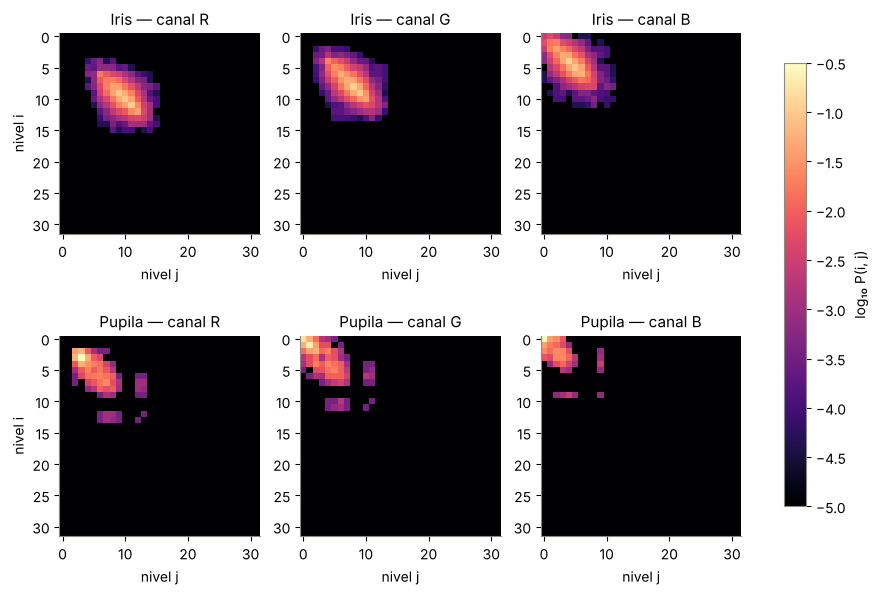

In [10]:
# GLCM promedio del iris y de la pupila en cada canal (32 niveles, escala logarítmica)
fig, ejes = plt.subplots(2, 3, figsize=(11, 7.2))
for fila, nombre in enumerate(["iris", "pupila"]):
    for col, canal in enumerate(de.CANALES):
        P = matrices[(nombre, canal, L0)]
        ax = ejes[fila, col]
        im = ax.imshow(np.log10(P + 1e-5), cmap="magma", vmin=-5, vmax=-0.5, origin="upper")
        ax.set_title(f"{nombre.capitalize()} — canal {canal}")
        ax.set_xlabel("nivel j")
        if col == 0:
            ax.set_ylabel("nivel i")
        ax.grid(False)
fig.colorbar(im, ax=ejes, shrink=0.8, label="log₁₀ P(i, j)")
fig.savefig(carpeta_res / "3_1_4_glcm_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultados**: acá se ven las 6 GLCM a 32 niveles, para cada canal, para el iris y la pupila. El nivel i es el nivel de gris del píxel y el nivel j es el de su vecino. Mientras más amarilla sea una celda, más frecuente es la aparición de esa combinación de niveles de gris, las probabilidades van de 0,1 a 0,00001, así que usamos la escala logarítmica para representarlas mejor.
1. La diagonal (i = j) son los pares de vecinos con el mismo nivel. Cuanto más pegada a la diagonal está la mancha, más suave es la textura. Se ve que los píxeles del iris se alejan más que los de la pupila, esto tiene sentido porque el iris tiene más variaciones en su textura que la pupila.
2. Lo lejos que la mancha está de la diagonal, en la dirección perpendicular, mide cuánto cambia el gris de un píxel a su vecino. Eso es el contraste.
3. Dónde cae la mancha a lo largo de la diagonal dice si la región es clara u oscura. Cuánto se estira a lo largo de la diagonal dice cuántos niveles distintos ocupa la región, es decir, su dispersión.

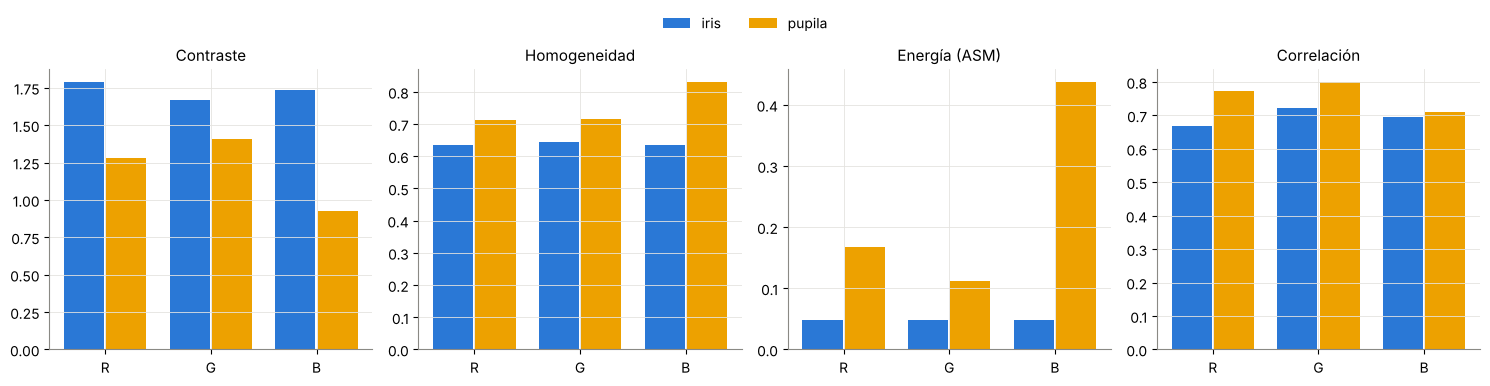

In [11]:
# Atributos por canal: iris vs pupila (32 niveles)
t = tabla_tx[tabla_tx.niveles == L0]
atributos = {"contraste": "Contraste", "homogeneidad": "Homogeneidad",
             "energia": "Energía (ASM)", "correlacion": "Correlación"}
x = np.arange(len(de.CANALES))
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (a, titulo) in zip(ejes, atributos.items()):
    for k, (nombre, desplaz) in enumerate([("iris", -0.2), ("pupila", 0.2)]):
        v = t[t.region == nombre].set_index("canal").loc[list(de.CANALES), a]
        ax.bar(x + desplaz, v, width=0.38, color=COLOR_REGION[nombre], label=nombre)
    ax.set_xticks(x, list(de.CANALES))
    ax.set_title(titulo)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="upper center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 1.08))
plt.tight_layout()
fig.savefig(carpeta_res / "3_1_5_glcm_atributos.png", dpi=150, bbox_inches="tight")
plt.show()

**Verificación.** La GLCM propia coincide con la de scikit-image (los cuatro atributos iguales hasta la tercera cifra) sobre la ROI completa, así que la implementación es correcta y se puede usar con la región del iris.

**Discusión (segundo orden).**

*Pupila vs iris.* La GLCM del iris es una "nube" ancha a lo largo de la diagonal (vecinos con niveles parecidos pero no iguales); la de la pupila está concentrada en la esquina de niveles bajos. Con 32 niveles, el iris tiene **mayor contraste** (1,67–1,79 contra 0,92–1,41), **menor homogeneidad** (0,64 contra 0,71–0,83) y, sobre todo, **mucha menor energía** (0,048–0,049 contra 0,11–0,44). La energía es el atributo más discriminativo: de 2 a 9 veces mayor en la pupila, porque allí unas pocas combinaciones de niveles oscuros se repiten muchísimo. La correlación es algo mayor en la pupila (0,71–0,80 contra 0,67–0,72): la pupila no tiene textura propia, solo un gradiente suave del centro oscuro al borde, y en un gradiente suave cada píxel predice bien a su vecino.

**¿Qué canal aporta más riqueza textural?** Las diferencias entre canales en el iris son **chicas**, pero apuntan en el mismo sentido que el primer orden:

* **G** tiene la mayor entropía y el mayor desvío, y además la **mayor correlación** (0,721): sus variaciones son *estructuradas* (estrías y criptas que ocupan varios píxeles), no ruido. Es el canal con más información de la textura del estroma.
* **R** tiene el mayor contraste local (1,79), pero la menor correlación (0,668): parte de esa variación de píxel a píxel es ruido.
* **B** queda en valores intermedios (contraste 1,73, correlación 0,695). Es el canal más oscuro (media 37: la melanina absorbe el azul), así que su textura se apoya en menos niveles de gris.

*32 vs 64 niveles.* El contraste se multiplica por 3,6–3,9 al pasar de 32 a 64 niveles (cerca de 4: al duplicar los niveles cada diferencia i−j se duplica y su cuadrado se multiplica por 4) y la energía y la homogeneidad bajan: son atributos que **dependen de la cuantización**, así que solo se pueden comparar con la misma cantidad de niveles. La correlación casi no cambia (0,67–0,73 en ambos casos): es el atributo más robusto. Además, con 64 niveles el orden de los canales en contraste cambia (B 6,57 > R 6,48 > G 6,46, contra R > B > G con 32): la diferencia de contraste entre canales es del orden del efecto de la cuantización y no es concluyente; la de correlación (G > B > R) se mantiene con 32 y con 64 niveles.

## 5. Conclusiones

1. **Forma.** En el frame de 5 s la pupila (máscara Watershed + erosión) tiene A = 204 px, P = 54,3 px, diámetro equivalente 16,1 px, circularidad 0,77 y excentricidad 0,66. La deformación respecto de un círculo se debe sobre todo a la medición (pupila de ~16 px, reflejo especular pegado, vista oblicua, compresión), no a la fisiología. La erosión cambia el área (−35 %) pero no la forma ni el centroide.
2. **Primer orden.** La media separa claramente pupila e iris en los tres canales. En el iris, R > G > B en intensidad (iris claro, verde-marrón); G tiene la mayor entropía y el mayor desvío.
3. **Segundo orden.** La **energía** es el atributo GLCM que más discrimina pupila de iris (2 a 9 veces mayor en la pupila). En el estroma iridiano **G es el canal con más riqueza textural** (mayor entropía, desvío y correlación; la correlación mantiene el orden G > B > R con 32 y 64 niveles). R tiene más contraste pero menos correlación (más ruido) y B queda en valores intermedios. Las diferencias entre canales son chicas porque el video guarda el color submuestreado (4:2:0) y el detalle fino viene de la luminancia.
4. El contraste, la energía y la homogeneidad dependen de la cantidad de niveles: solo se comparan entre sí con la misma cuantización. La correlación es casi invariante.

Limitaciones: un solo frame y una sola persona; la región del iris excluye el párpado y los reflejos con umbrales fijos (`modulo3.region_iris`); con un iris de ~70 px de diámetro y video comprimido, la textura fina del estroma (criptas de 1–2 px) se pierde en parte. Los valores dependen de la ROI de `config.yaml` (el CLAHE de la segmentación trabaja por bloques de la ROI).